# Phân tích phiên ONOFF qua 8 lần chạy

Notebook chỉ đọc dữ liệu thực tế trong `results/onoff/run_01` đến `run_08`. Khác với MMPP, ON/OFF không sinh phiên mới: 60 client tồn tại xuyên suốt run và luân phiên giữa ON/OFF. Vì vậy notebook phân tích hai đại lượng đúng với mô hình:

- **Số phiên đang ON** tại từng giây, đọc từ `designed_rate.csv` (cột `lambda_sessions` trong kịch bản này thực chất là số nguồn ON).
- **Request/giây thực sinh**, gom `kind=request` trong `arrival_trace.csv` theo các khoảng 10 giây.

Tám run được đặt nối tiếp trên một trục thời gian tích lũy; mỗi run được vẽ như một đoạn độc lập để không nội suy qua ranh giới.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display

BIN_SEC = 10.0
N_SOURCES = 60
RATE_ON = 1.5  # request/s cho mỗi nguồn đang ON
RUN_IDS = [f"run_{i:02d}" for i in range(1, 9)]

# Hoạt động khi kernel được mở từ thư mục gốc repository hoặc từ notebooks/dataset/.
ROOT_CANDIDATES = [Path("../../dataset/raw/onoff"), Path("dataset/raw/onoff")]
RESULTS_DIR = next((p for p in ROOT_CANDIDATES if p.is_dir()), None)
if RESULTS_DIR is None:
    tried = ", ".join(str(p.resolve()) for p in ROOT_CANDIDATES)
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu ON/OFF. Đã thử: {tried}")

print(f"Đọc dữ liệu từ: {RESULTS_DIR.resolve()}")

Đọc dữ liệu từ: F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\math-load-testing\results\onoff


In [2]:
def read_run_duration(run_dir: Path) -> float:
    """Đọc thời lượng run từ metadata; không suy ra từ arrival cuối cùng."""
    trace_meta_path = run_dir / "trace_meta.json"
    meta_path = run_dir / "meta.json"

    if trace_meta_path.is_file():
        duration = json.loads(trace_meta_path.read_text(encoding="utf-8"))["duration"]
    elif meta_path.is_file():
        duration = json.loads(meta_path.read_text(encoding="utf-8"))["duration_sec"]
    else:
        raise FileNotFoundError(
            f"{run_dir}: thiếu trace_meta.json và meta.json để xác định thời lượng chính xác"
        )

    duration = float(duration)
    if not np.isfinite(duration) or duration <= 0:
        raise ValueError(f"{run_dir}: thời lượng không hợp lệ: {duration}")
    return duration


run_series = []
summary_rows = []
cumulative_sec = 0.0

for run_id in RUN_IDS:
    run_dir = RESULTS_DIR / run_id
    trace_path = run_dir / "arrival_trace.csv"
    rate_path = run_dir / "designed_rate.csv"
    driver_path = run_dir / "driver_report.json"
    for path in (trace_path, rate_path, driver_path):
        if not path.is_file():
            raise FileNotFoundError(f"Thiếu dữ liệu đầu vào: {path}")

    duration_sec = read_run_duration(run_dir)
    trace = pd.read_csv(trace_path)
    rate = pd.read_csv(rate_path)
    driver = json.loads(driver_path.read_text(encoding="utf-8"))

    missing_trace = {"t", "kind", "source"}.difference(trace.columns)
    missing_rate = {"t", "lambda_sessions", "expected_rps"}.difference(rate.columns)
    if missing_trace:
        raise ValueError(f"{trace_path}: thiếu cột {sorted(missing_trace)}")
    if missing_rate:
        raise ValueError(f"{rate_path}: thiếu cột {sorted(missing_rate)}")

    trace["t"] = pd.to_numeric(trace["t"], errors="raise")
    rate["t"] = pd.to_numeric(rate["t"], errors="raise")
    rate["n_on"] = pd.to_numeric(rate["lambda_sessions"], errors="raise")
    rate["expected_rps"] = pd.to_numeric(rate["expected_rps"], errors="raise")

    unexpected_kinds = sorted(set(trace["kind"].dropna()) - {"request"})
    if unexpected_kinds:
        raise ValueError(f"{trace_path}: kind không thuộc ON/OFF: {unexpected_kinds}")
    requests = trace.loc[trace["kind"].eq("request"), ["t", "source"]].copy()
    invalid_requests = requests.loc[(requests["t"] < 0) | (requests["t"] >= duration_sec)]
    if not invalid_requests.empty:
        raise ValueError(
            f"{trace_path}: có {len(invalid_requests)} request nằm ngoài [0, {duration_sec})"
        )

    if ((rate["n_on"] < 0) | (rate["n_on"] > N_SOURCES)).any():
        raise ValueError(f"{rate_path}: số nguồn ON nằm ngoài [0, {N_SOURCES}]")
    if not np.allclose(rate["expected_rps"], rate["n_on"] * RATE_ON):
        raise ValueError(f"{rate_path}: expected_rps không bằng n_on × RATE_ON")

    # Giữ bin cuối ngắn hơn 10 giây nếu thời lượng run không chia hết cho BIN_SEC.
    local_edges = np.arange(0.0, duration_sec, BIN_SEC)
    local_edges = np.append(local_edges, duration_sec)
    counts, _ = np.histogram(requests["t"].to_numpy(), bins=local_edges)
    bin_widths = np.diff(local_edges)
    request_rates = counts / bin_widths
    expected_bin_rates = np.array([
        rate.loc[(rate["t"] >= left) & (rate["t"] < right), "expected_rps"].mean()
        for left, right in zip(local_edges[:-1], local_edges[1:])
    ])

    cumulative_edges_min = (cumulative_sec + local_edges) / 60.0
    cumulative_t_min = (cumulative_sec + rate["t"].to_numpy()) / 60.0
    run_series.append({
        "run_id": run_id,
        "duration_sec": duration_sec,
        "t_min": cumulative_t_min,
        "edges_min": cumulative_edges_min,
        "n_on": rate["n_on"].to_numpy(),
        "request_rates": request_rates,
        "expected_bin_rates": expected_bin_rates,
        "start_min": cumulative_sec / 60.0,
        "end_min": (cumulative_sec + duration_sec) / 60.0,
    })
    actual_mean_rps = len(requests) / duration_sec
    designed_mean_rps = float(rate["expected_rps"].mean())
    summary_rows.append({
        "Run": run_id,
        "Thời lượng (phút)": duration_sec / 60.0,
        "Phiên ON trung bình": float(rate["n_on"].mean()),
        "Phiên ON nhỏ nhất": int(rate["n_on"].min()),
        "Phiên ON lớn nhất": int(rate["n_on"].max()),
        "Tổng request": int(len(requests)),
        "RPS thiết kế trung bình": designed_mean_rps,
        "RPS thực sinh trung bình": actual_mean_rps,
        "RPS cực đại (bin 10 giây)": float(request_rates.max()) if len(request_rates) else 0.0,
        "Arrival bị bỏ": int(driver.get("dropped", 0)),
    })
    cumulative_sec += duration_sec

summary = pd.DataFrame(summary_rows)
total_minutes = cumulative_sec / 60.0
print(f"Đã đọc {len(run_series)} run; tổng thời lượng: {total_minutes:.2f} phút")

Đã đọc 8 run; tổng thời lượng: 240.00 phút


## Số phiên đang ON trên thời gian tích lũy

Mỗi đường màu là một run độc lập. Đường ngang chấm gạch là số phiên ON trung bình gộp từ tám run; các đường dọc nét đứt đánh dấu ranh giới run.

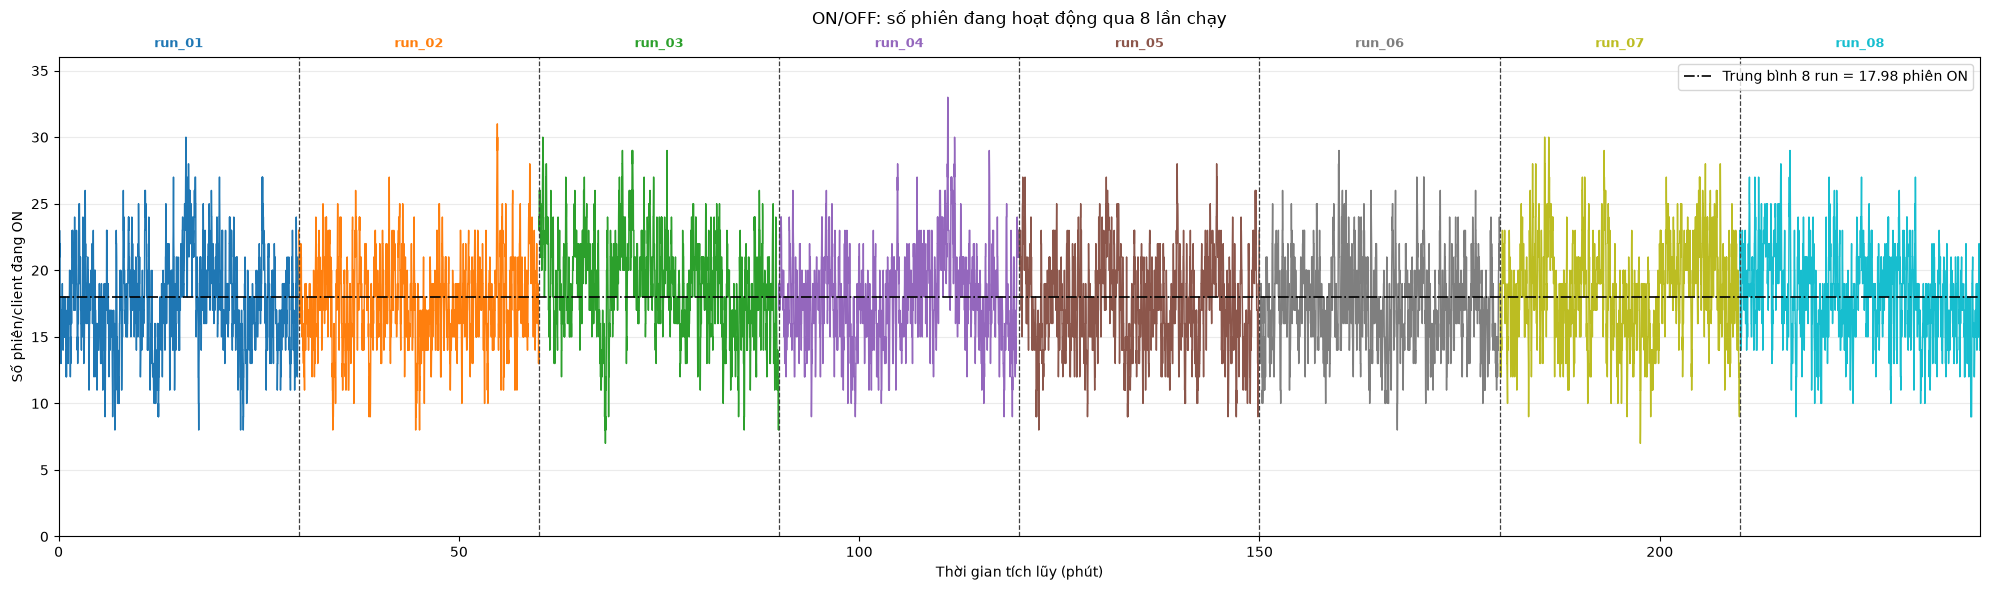

In [3]:
fig, ax = plt.subplots(figsize=(20, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(run_series)))

for idx, (item, color) in enumerate(zip(run_series, colors)):
    ax.plot(item["t_min"], item["n_on"], color=color, linewidth=1.05)
    midpoint = (item["start_min"] + item["end_min"]) / 2.0
    ax.text(
        midpoint, 1.015, item["run_id"],
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold", color=color,
        clip_on=False,
    )
    if idx > 0:
        ax.axvline(item["start_min"], color="0.25", linestyle="--", linewidth=0.9)

pooled_mean_on = np.average(
    summary["Phiên ON trung bình"], weights=summary["Thời lượng (phút)"]
)
ax.axhline(
    pooled_mean_on, color="black", linestyle="-.", linewidth=1.2,
    label=f"Trung bình 8 run = {pooled_mean_on:.2f} phiên ON",
)
ax.set_xlim(0, total_minutes)
ax.set_ylim(0, max(item["n_on"].max() for item in run_series) + 3)
ax.set_xlabel("Thời gian tích lũy (phút)")
ax.set_ylabel("Số phiên/client đang ON")
ax.set_title("ON/OFF: số phiên đang hoạt động qua 8 lần chạy", pad=24)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
ax.margins(x=0)
fig.tight_layout()
plt.show()

## Request/giây thiết kế và thực sinh

Đường liền là số request thực sinh trong từng bin 10 giây. Đường đứt là $E[\mathrm{RPS}]=1{,}5\,N_{\mathrm{ON}}$ lấy trung bình trên cùng bin. Chênh lệch ngắn hạn giữa hai đường là nhiễu Poisson; `Arrival bị bỏ > 0` mới cho biết driver không phát đủ trace.

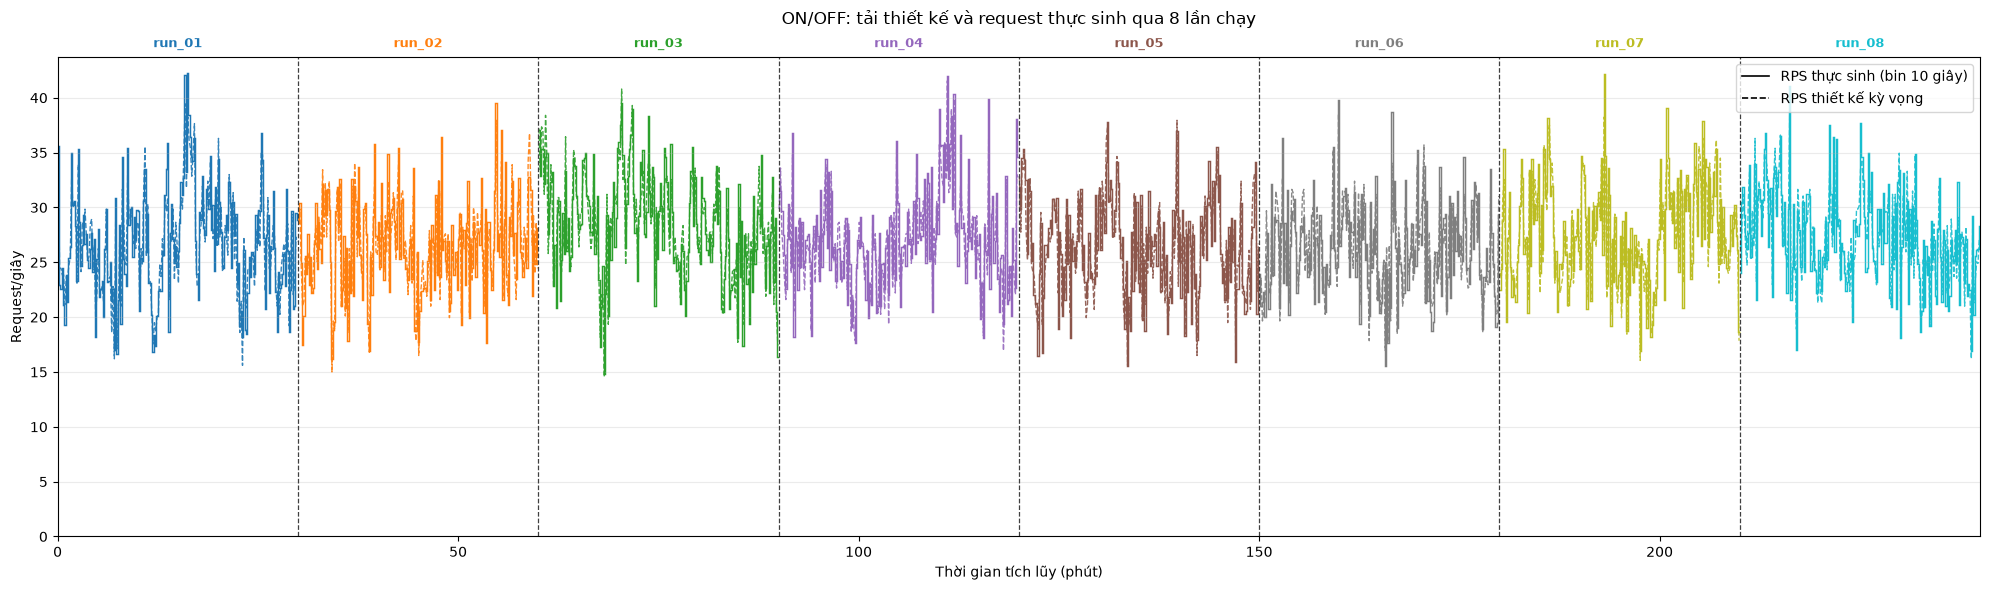

In [4]:
fig, ax = plt.subplots(figsize=(20, 6))

for idx, (item, color) in enumerate(zip(run_series, colors)):
    centers_min = (item["edges_min"][:-1] + item["edges_min"][1:]) / 2.0
    ax.stairs(
        item["request_rates"], item["edges_min"], baseline=None,
        color=color, linewidth=1.05,
    )
    ax.plot(
        centers_min, item["expected_bin_rates"],
        color=color, linestyle="--", linewidth=1.0, alpha=0.9,
    )
    midpoint = (item["start_min"] + item["end_min"]) / 2.0
    ax.text(
        midpoint, 1.015, item["run_id"],
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold", color=color,
        clip_on=False,
    )
    if idx > 0:
        ax.axvline(item["start_min"], color="0.25", linestyle="--", linewidth=0.9)

style_legend = [
    Line2D([0], [0], color="black", linewidth=1.2, label="RPS thực sinh (bin 10 giây)"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.2, label="RPS thiết kế kỳ vọng"),
]
ax.legend(handles=style_legend, loc="upper right")
ax.set_xlim(0, total_minutes)
ax.set_ylim(bottom=0)
ax.set_xlabel("Thời gian tích lũy (phút)")
ax.set_ylabel("Request/giây")
ax.set_title("ON/OFF: tải thiết kế và request thực sinh qua 8 lần chạy", pad=24)
ax.grid(axis="y", alpha=0.25)
ax.margins(x=0)
fig.tight_layout()
plt.show()

## Thống kê theo từng lần chạy

`RPS thiết kế trung bình` là trung bình của cường độ kỳ vọng theo trạng thái ON/OFF; `RPS thực sinh trung bình` là tổng số event request chia cho đúng thời lượng run.

In [5]:
display(
    summary.style.format({
        "Thời lượng (phút)": "{:.2f}",
        "Phiên ON trung bình": "{:.3f}",
        "Phiên ON nhỏ nhất": "{:,.0f}",
        "Phiên ON lớn nhất": "{:,.0f}",
        "Tổng request": "{:,.0f}",
        "RPS thiết kế trung bình": "{:.3f}",
        "RPS thực sinh trung bình": "{:.3f}",
        "RPS cực đại (bin 10 giây)": "{:.3f}",
        "Arrival bị bỏ": "{:,.0f}",
    })
)

total_duration_sec = summary["Thời lượng (phút)"].sum() * 60.0
total_requests = summary["Tổng request"].sum()
pooled_designed_rps = np.average(
    summary["RPS thiết kế trung bình"], weights=summary["Thời lượng (phút)"]
)
pooled_actual_rps = total_requests / total_duration_sec
overall = pd.DataFrame([{
    "Tổng thời lượng (phút)": total_duration_sec / 60.0,
    "Tổng request": int(total_requests),
    "Phiên ON trung bình": pooled_mean_on,
    "RPS thiết kế gộp": pooled_designed_rps,
    "RPS thực sinh gộp": pooled_actual_rps,
    "Sai lệch thực/thiết kế (%)": 100.0 * (pooled_actual_rps / pooled_designed_rps - 1.0),
    "Tổng arrival bị bỏ": int(summary["Arrival bị bỏ"].sum()),
}])
display(overall.style.format({
    "Tổng thời lượng (phút)": "{:.2f}",
    "Tổng request": "{:,.0f}",
    "Phiên ON trung bình": "{:.3f}",
    "RPS thiết kế gộp": "{:.3f}",
    "RPS thực sinh gộp": "{:.3f}",
    "Sai lệch thực/thiết kế (%)": "{:+.3f}",
    "Tổng arrival bị bỏ": "{:,.0f}",
}))

,Run,Thời lượng (phút),Phiên ON trung bình,Phiên ON nhỏ nhất,Phiên ON lớn nhất,Tổng request,RPS thiết kế trung bình,RPS thực sinh trung bình,RPS cực đại (bin 10 giây),Arrival bị bỏ
0,run_01,30.00,17.724,8,30,"47,978",26.586,26.654,42.300,0
1,run_02,30.00,17.598,8,31,"47,536",26.398,26.409,39.500,0
2,run_03,30.00,18.940,7,30,"50,916",28.410,28.287,39.500,0
3,run_04,30.00,17.998,9,33,"48,807",26.997,27.115,42.000,0
4,run_05,30.00,17.530,8,28,"47,444",26.295,26.358,37.800,0
5,run_06,30.00,17.455,8,29,"46,998",26.183,26.110,39.800,0
6,run_07,30.00,18.430,7,30,"49,768",27.645,27.649,42.200,0
7,run_08,30.00,18.181,9,29,"48,968",27.272,27.204,41.100,0


,Tổng thời lượng (phút),Tổng request,Phiên ON trung bình,RPS thiết kế gộp,RPS thực sinh gộp,Sai lệch thực/thiết kế (%),Tổng arrival bị bỏ
0,240.00,"388,415",17.982,26.973,26.973,+0.001,0
